<a href="https://colab.research.google.com/github/VikaIz/intro-ai/blob/main/lab3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа № 3

## Задание
Решите пожалуйста следующую задачу.

1. Примените методы снижения размерности (до двумерного представления
n_components=2) перечисленные ниже для данных находящихся пo
[ссылке](https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view). Здесь - метка (учитель) является столбец / атрибут - `outcome`. Предоставьте результаты, используя следующие ядерные функции:
- PCA
- LDA
- TruncatedSVD
- Kernel PCA (перебрав все ядерные функции - ('linear', 'poly', 'rbf', sigmoid',
'cosine', 'precomputed')

## Загрузка данных

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA, KernelPCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.metrics.pairwise import rbf_kernel

In [ ]:
! gdown --fuzzy 'https://drive.google.com/file/d/1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec/view'

Downloading...
From: https://drive.google.com/uc?id=1LBDnhITL0Wqwp5G6M6IBI-SSz8BIoNec
To: /content/diabetes.csv
100% 23.1k/23.1k [00:00<00:00, 40.4MB/s]


In [ ]:
df = pd.read_csv('/content/diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


##  О датасете
[Pima Indians Diabetes Database](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database/data)

Этот набор данных взят из Национального института диабета, заболеваний органов пищеварения и почек (NIDDK). Целью набора данных является диагностическое предсказание наличия у пациента диабета на основе определенных диагностических измерений, включенных в набор данных. На выбор этих экземпляров из более крупной базы данных было наложено несколько ограничений. В частности, все пациенты здесь — женщины не моложе 21 года, родом из индейцев Пима.

Наборы данных состоят из нескольких переменных медицинских предикторов и одной целевой переменной `Outcome`. Переменные-предикторы включают количество беременностей, которые были у пациентки, её индекс массы тела `BMI`, уровень инсулина, возраст и так далее. Всего в датасете 9 переменных:
- `Pregnancies` - количество беременностей;
- `Glucose` - концентрация глюкозы в плазме через 2 часа при пероральном тесте на толерантность к глюкозе;
- `BloodPressure` - диастолическое артериальное давление (мм рт. ст.);
- `SkinThickness` - толщина кожной складки трицепса (мм);
- `Insulin` - 2-часовой сывороточный инсулин (мкЕд/мл);
- `BMI` - Индекс массы тела (вес в кг/(рост в м)^2);
- `DiabetesPedigreeFunction` - функция оценки вероятности диабета на основе семейного анамнеза;
- `Age` - возраст (лет);
- `Outcome` - целевая переменная (0 или 1) 268 из 768 — 1 (больны), остальные — 0 (здоровы).



In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [ ]:
df.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [ ]:
zeros_count = (df == 0).sum()
print("Количество нулевых значений по каждому столбцу:")
print(zeros_count[zeros_count > 0])

Количество нулевых значений по каждому столбцу:
Pregnancies      111
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
Outcome          500
dtype: int64


In [ ]:
X = df.drop('Outcome', axis=1)
y = df['Outcome']

print(f"Уникальные классы в y: {np.unique(y)}")
print(f"Распределение классов: {y.value_counts().to_dict()}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nРазмер X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Распределение классов в train: {y_train.value_counts().to_dict()}")
print(f"Распределение классов в test:  {y_test.value_counts().to_dict()}")

Уникальные классы в y: [0 1]
Распределение классов: {0: 500, 1: 268}

Размер X_train: (614, 8), X_test: (154, 8)
Распределение классов в train: {0: 400, 1: 214}
Распределение классов в test:  {0: 100, 1: 54}


Предобработка (ПОСЛЕ разделения — без утечки данных)

In [ ]:
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
X_train[cols_with_zeros] = X_train[cols_with_zeros].replace(0, np.nan)
X_test[cols_with_zeros] = X_test[cols_with_zeros].replace(0, np.nan)


medians = X_train[cols_with_zeros].median()

X_train[cols_with_zeros] = X_train[cols_with_zeros].fillna(medians)
X_test[cols_with_zeros] = X_test[cols_with_zeros].fillna(medians)

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Метод PCA

PCA: объяснённая дисперсия = 0.4822
Форма X_pca_train: (614, 2)


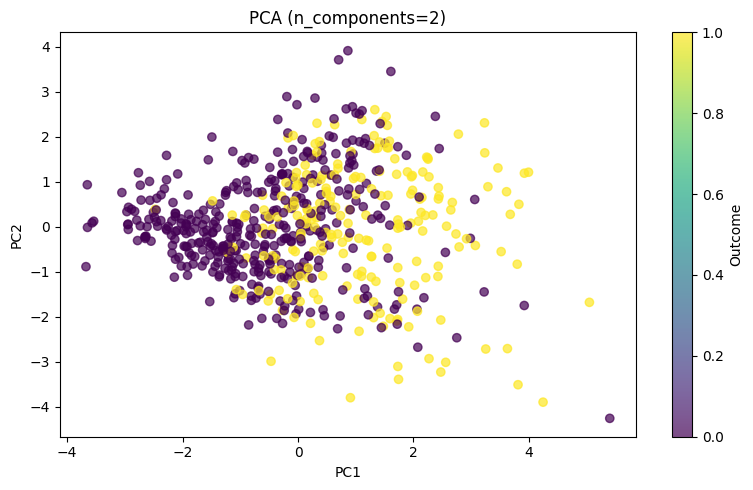

In [ ]:
pca = PCA(n_components=2, random_state=42)
X_pca_train = pca.fit_transform(X_train_scaled)
X_pca_test = pca.transform(X_test_scaled)

print(f"PCA: объяснённая дисперсия = {pca.explained_variance_ratio_.sum():.4f}")
print(f"Форма X_pca_train: {X_pca_train.shape}")


plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_pca_train[:, 0], X_pca_train[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('PCA (n_components=2)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

## Метод LDA

In [ ]:
df['Outcome'].unique()

array([1, 0])

Целевая переменная Outcome имеет только 2 уникальных значения (класса: 0 и 1).

LDA — метод с учителем. Для бинарной классификации (2 класса) максимальное число компонент = n_classes - 1 = 1.

Поэтому n_components=2 невозможно — используем 1.

LDA: объяснённая дисперсия = 1.0000
Форма X_lda_train: (614, 1)


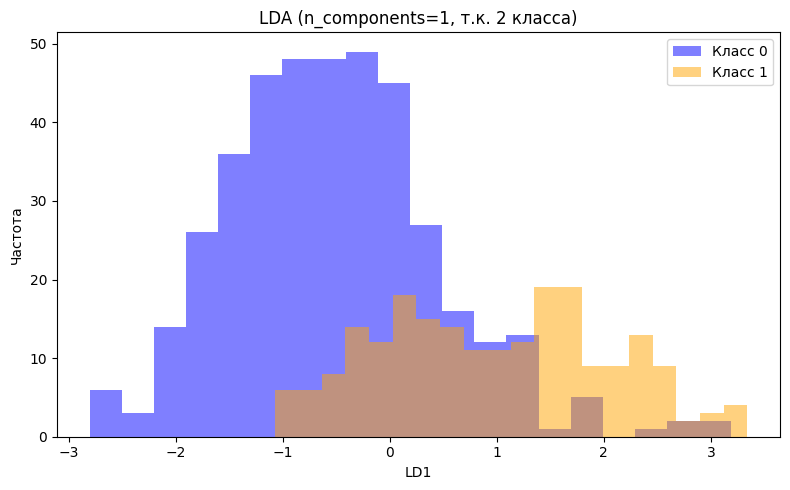

In [ ]:
lda = LDA(n_components=1)
X_lda_train = lda.fit_transform(X_train_scaled, y_train)
X_lda_test = lda.transform(X_test_scaled)

print(f"LDA: объяснённая дисперсия = {lda.explained_variance_ratio_.sum():.4f}")
print(f"Форма X_lda_train: {X_lda_train.shape}")

plt.figure(figsize=(8, 5))
for cls, color in zip([0, 1], ['blue', 'orange']):
    mask = y_train == cls
    plt.hist(X_lda_train[mask], bins=20, alpha=0.5, color=color, label=f'Класс {cls}')
plt.title('LDA (n_components=1, т.к. 2 класса)')
plt.xlabel('LD1')
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()
plt.show()

## Метод TruncatedSVD

TruncatedSVD: объяснённая дисперсия = 0.4822
Форма X_svd_train: (614, 2)


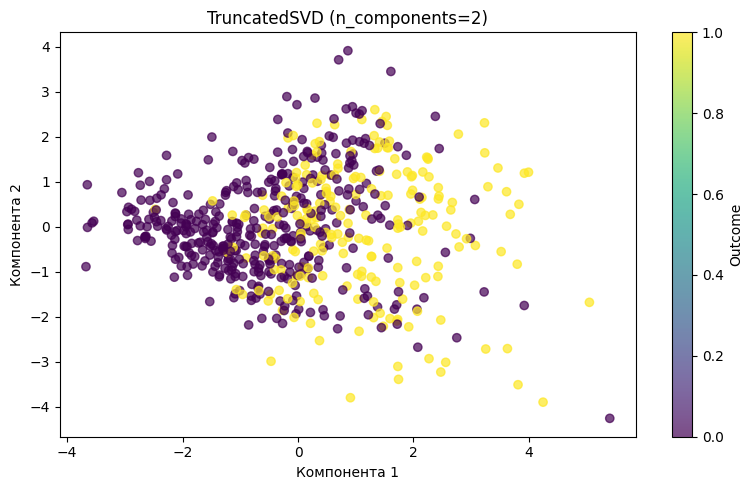

In [ ]:
svd = TruncatedSVD(n_components=2, random_state=42)
X_svd_train = svd.fit_transform(X_train_scaled)
X_svd_test = svd.transform(X_test_scaled)

print(f"TruncatedSVD: объяснённая дисперсия = {svd.explained_variance_ratio_.sum():.4f}")
print(f"Форма X_svd_train: {X_svd_train.shape}")

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_svd_train[:, 0], X_svd_train[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('TruncatedSVD (n_components=2)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

## Метод Kernel PCA

KernelPCA (rbf): форма = (614, 2)


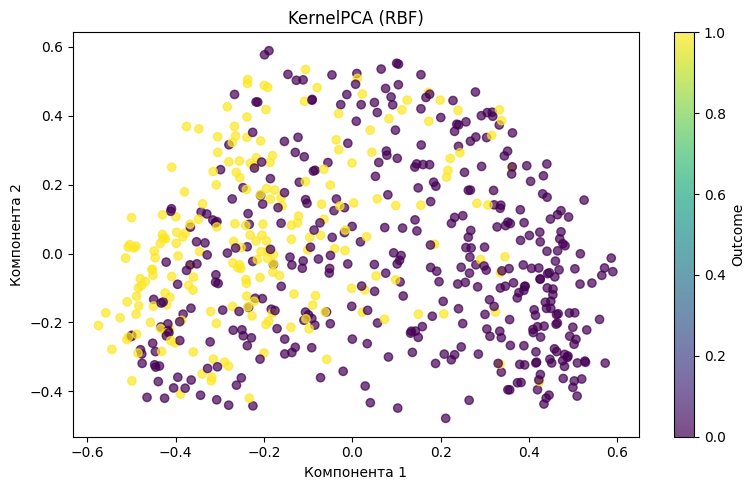

In [ ]:
kpca = KernelPCA(n_components=2, kernel='rbf', gamma=0.1, random_state=42)
X_kpca_train = kpca.fit_transform(X_train_scaled)
X_kpca_test = kpca.transform(X_test_scaled)

print(f"KernelPCA (rbf): форма = {X_kpca_train.shape}")

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_train[:, 0], X_kpca_train[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA (RBF)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `linear`

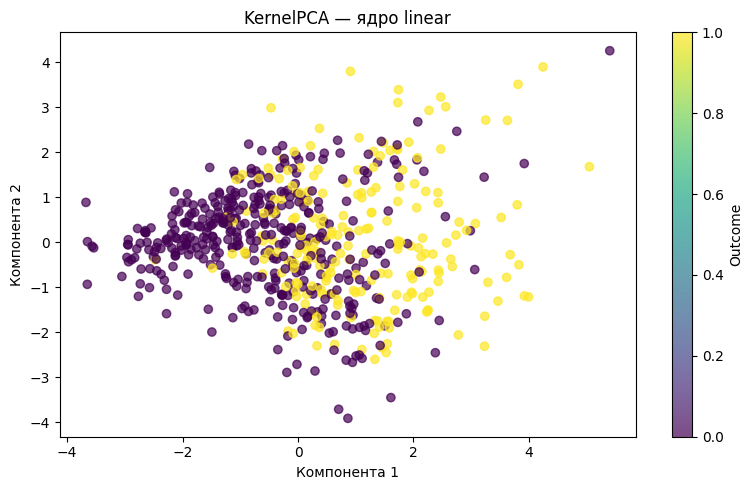

In [ ]:
kpca_linear = KernelPCA(n_components=2, kernel='linear', random_state=42)
X_kpca_lin = kpca_linear.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_lin[:, 0], X_kpca_lin[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро linear')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `poly`

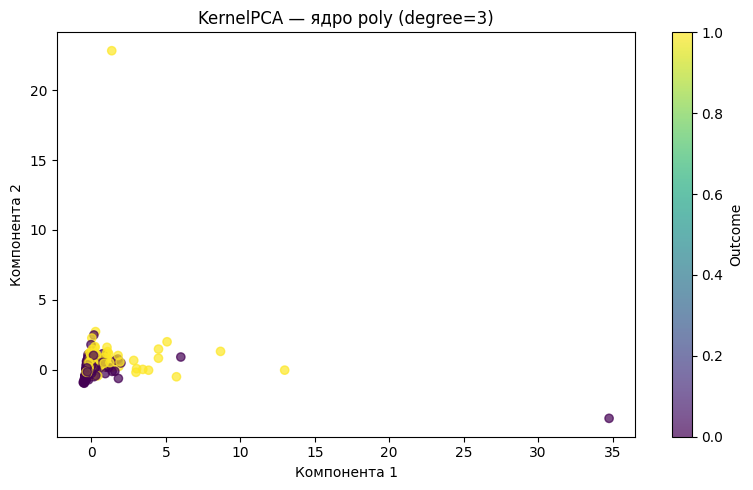

In [ ]:
kpca_poly = KernelPCA(n_components=2, kernel='poly', degree=3, gamma=0.1, coef0=1, random_state=42)
X_kpca_poly = kpca_poly.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_poly[:, 0], X_kpca_poly[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро poly (degree=3)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `rbf`

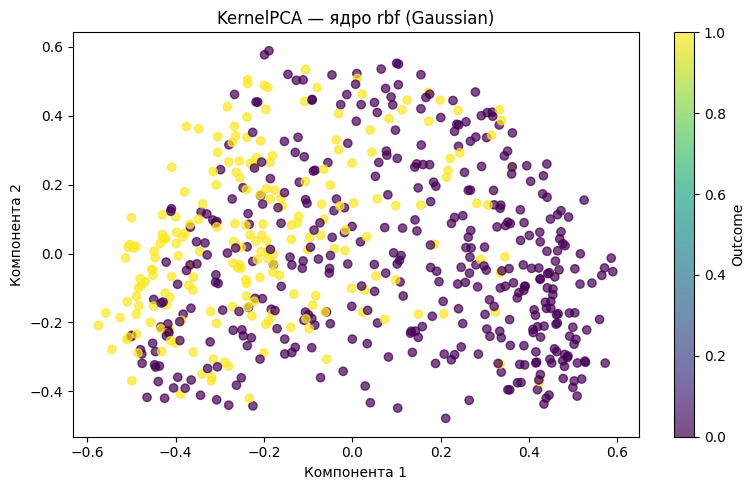

In [ ]:
kpca_rbf = KernelPCA(n_components=2, kernel='rbf', gamma=0.1, random_state=42)
X_kpca_rbf = kpca_rbf.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_rbf[:, 0], X_kpca_rbf[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро rbf (Gaussian)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `sigmoid`

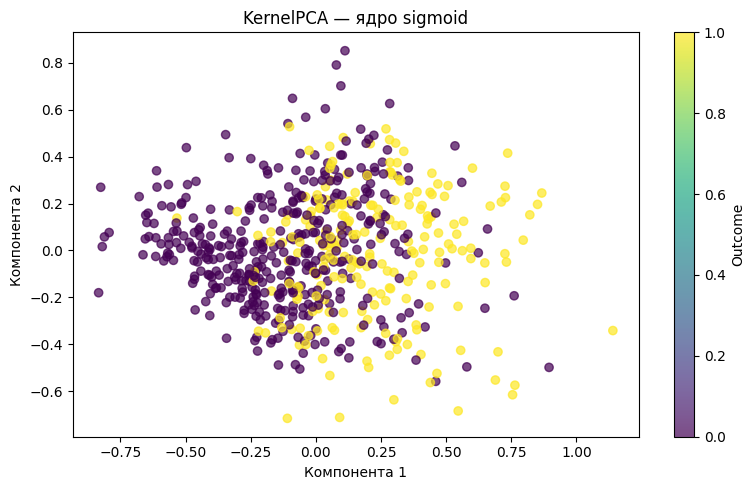

In [ ]:
kpca_sigmoid = KernelPCA(n_components=2, kernel='sigmoid', gamma=0.1, coef0=1, random_state=42)
X_kpca_sigmoid = kpca_sigmoid.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_sigmoid[:, 0], X_kpca_sigmoid[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро sigmoid')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `cosine`

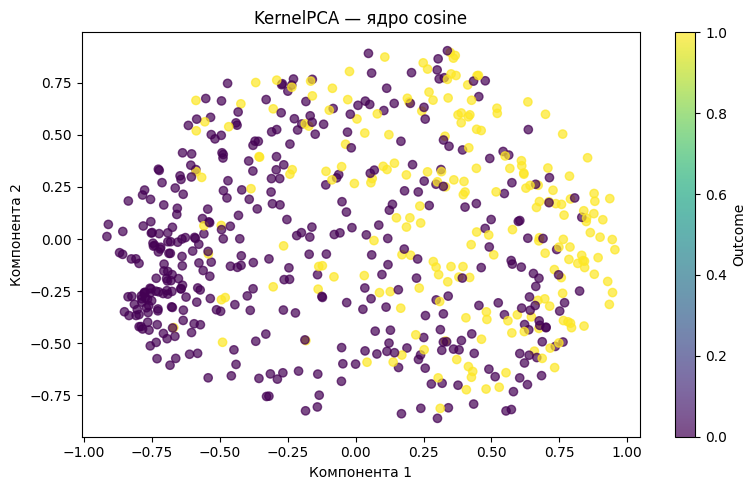

In [ ]:
kpca_cosine = KernelPCA(n_components=2, kernel='cosine', random_state=42)
X_kpca_cosine = kpca_cosine.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_cosine[:, 0], X_kpca_cosine[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро cosine')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()

###  Ядерная функция `precomputed`

Форма Gram-матрицы K_train: (614, 614)
Форма X_kpca_pre_train: (614, 2)


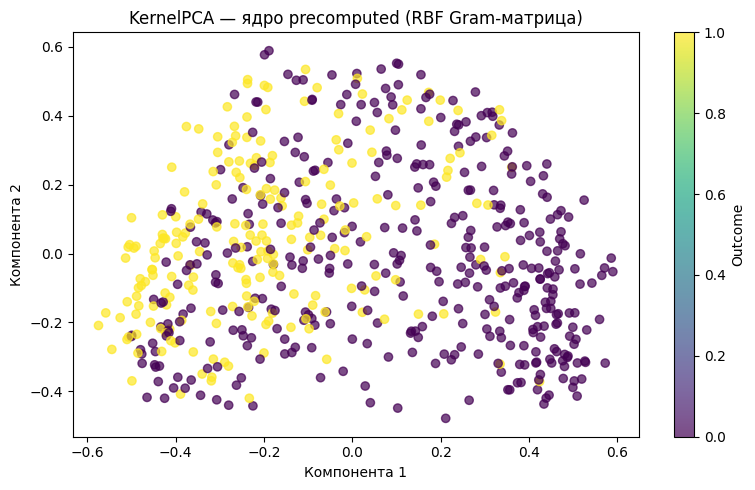

In [ ]:
K_train = rbf_kernel(X_train_scaled, gamma=0.1)
K_test = rbf_kernel(X_test_scaled, X_train_scaled, gamma=0.1)

kpca_pre = KernelPCA(n_components=2, kernel='precomputed', random_state=42)
X_kpca_pre_train = kpca_pre.fit_transform(K_train)
X_kpca_pre_test = kpca_pre.transform(K_test)

print(f"Форма Gram-матрицы K_train: {K_train.shape}")
print(f"Форма X_kpca_pre_train: {X_kpca_pre_train.shape}")

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_kpca_pre_train[:, 0], X_kpca_pre_train[:, 1], c=y_train, cmap='viridis', alpha=0.7)
plt.title('KernelPCA — ядро precomputed (RBF Gram-матрица)')
plt.xlabel('Компонента 1')
plt.ylabel('Компонента 2')
plt.colorbar(scatter, label='Outcome')
plt.tight_layout()
plt.show()